In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#1. Obtención de los Datos

In [2]:
import yfinance as yf

In [3]:
df = yf.download('AAPL', start='2010-07-01', end='2026-08-01')

/tmp/ipykernel_3180/1168041575.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download('AAPL', start='2010-07-01', end='2026-08-01')
[*********************100%***********************]  1 of 1 completed


In [4]:
df

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2010-07-01,7.438354,7.627547,7.280895,7.612579,1022896000
2010-07-02,7.392252,7.511695,7.280293,7.498522,693842800
2010-07-06,7.442846,7.567676,7.368905,7.513792,615235600
2010-07-07,7.743394,7.746388,7.476371,7.498522,654556000
2010-07-08,7.726033,7.870023,7.630240,7.857450,738144400
...,...,...,...,...,...
2026-07-27,336.910004,339.570007,334.019989,334.540009,49604300
2026-07-28,340.079987,342.890015,335.600006,340.029999,51859000


##Extraemos la serie temporal del precio de cierre de la acción de apple


In [5]:
time_series =  df[('Close', 'AAPL')]

In [6]:
Porcentagem_de_treino = 0.7 #1 = 100%, 0.7 = 70%
train_size = round(len(time_series) * Porcentagem_de_treino)
data_train = time_series[:train_size]
data_test = time_series[train_size:]

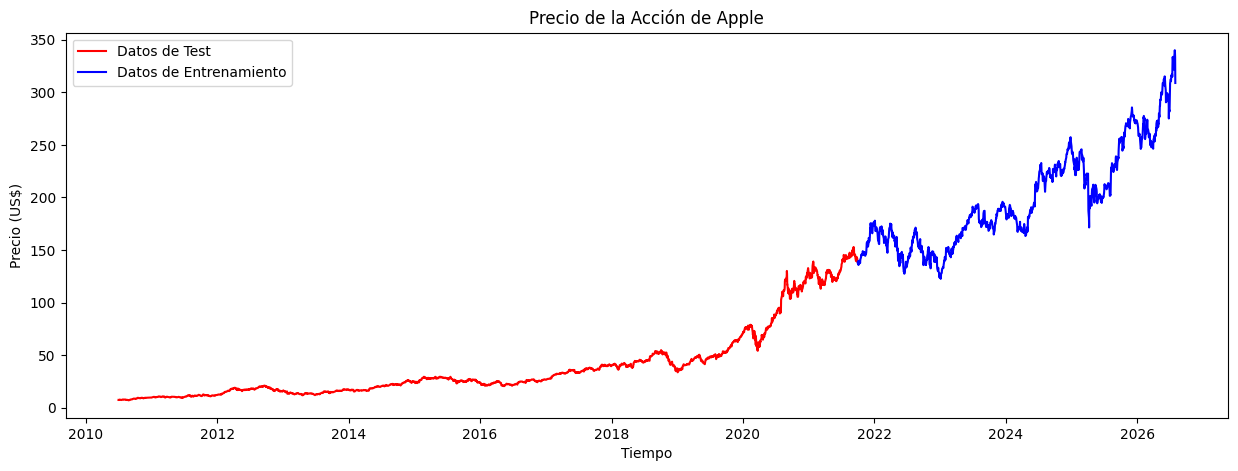

In [7]:
fig, ax = plt.subplots(figsize=(15, 5))
_ = plt.plot(data_train, color="r")
_ = plt.plot(data_test, color="b")
_ = plt.xlabel("Tiempo")
_ = plt.ylabel("Precio (US$)")
_ = plt.legend([ 'Datos de Test', 'Datos de Entrenamiento'])
_ = plt.title("Precio de la Acción de Apple")
plt.show()

##Multiple Splits Time Series Cross Validation

In [9]:
def K_fold(trianing_dataset, Kfold):
  n_D = len(trianing_dataset)
  # Calculate the split position for each time
  D_train_lst = list()
  D_validation_lst = list()
  for i in range(1, n_splits + 1):
    # Calculate train size and Vlidation size
    s_train_i = i * n_D // (n_splits + 1) + n_D % (n_splits + 1)
    s_validation_i = n_D //(n_splits + 1)
    D_train_i = trianing_dataset.iloc[0 : s_train_i]
    D_validation_i = trianing_dataset.iloc[s_train_i : s_train_i + s_validation_i]
    D_train_lst.append(D_train_i)
    D_validation_lst.append(D_validation_i)
  return D_train_lst, D_validation_lst

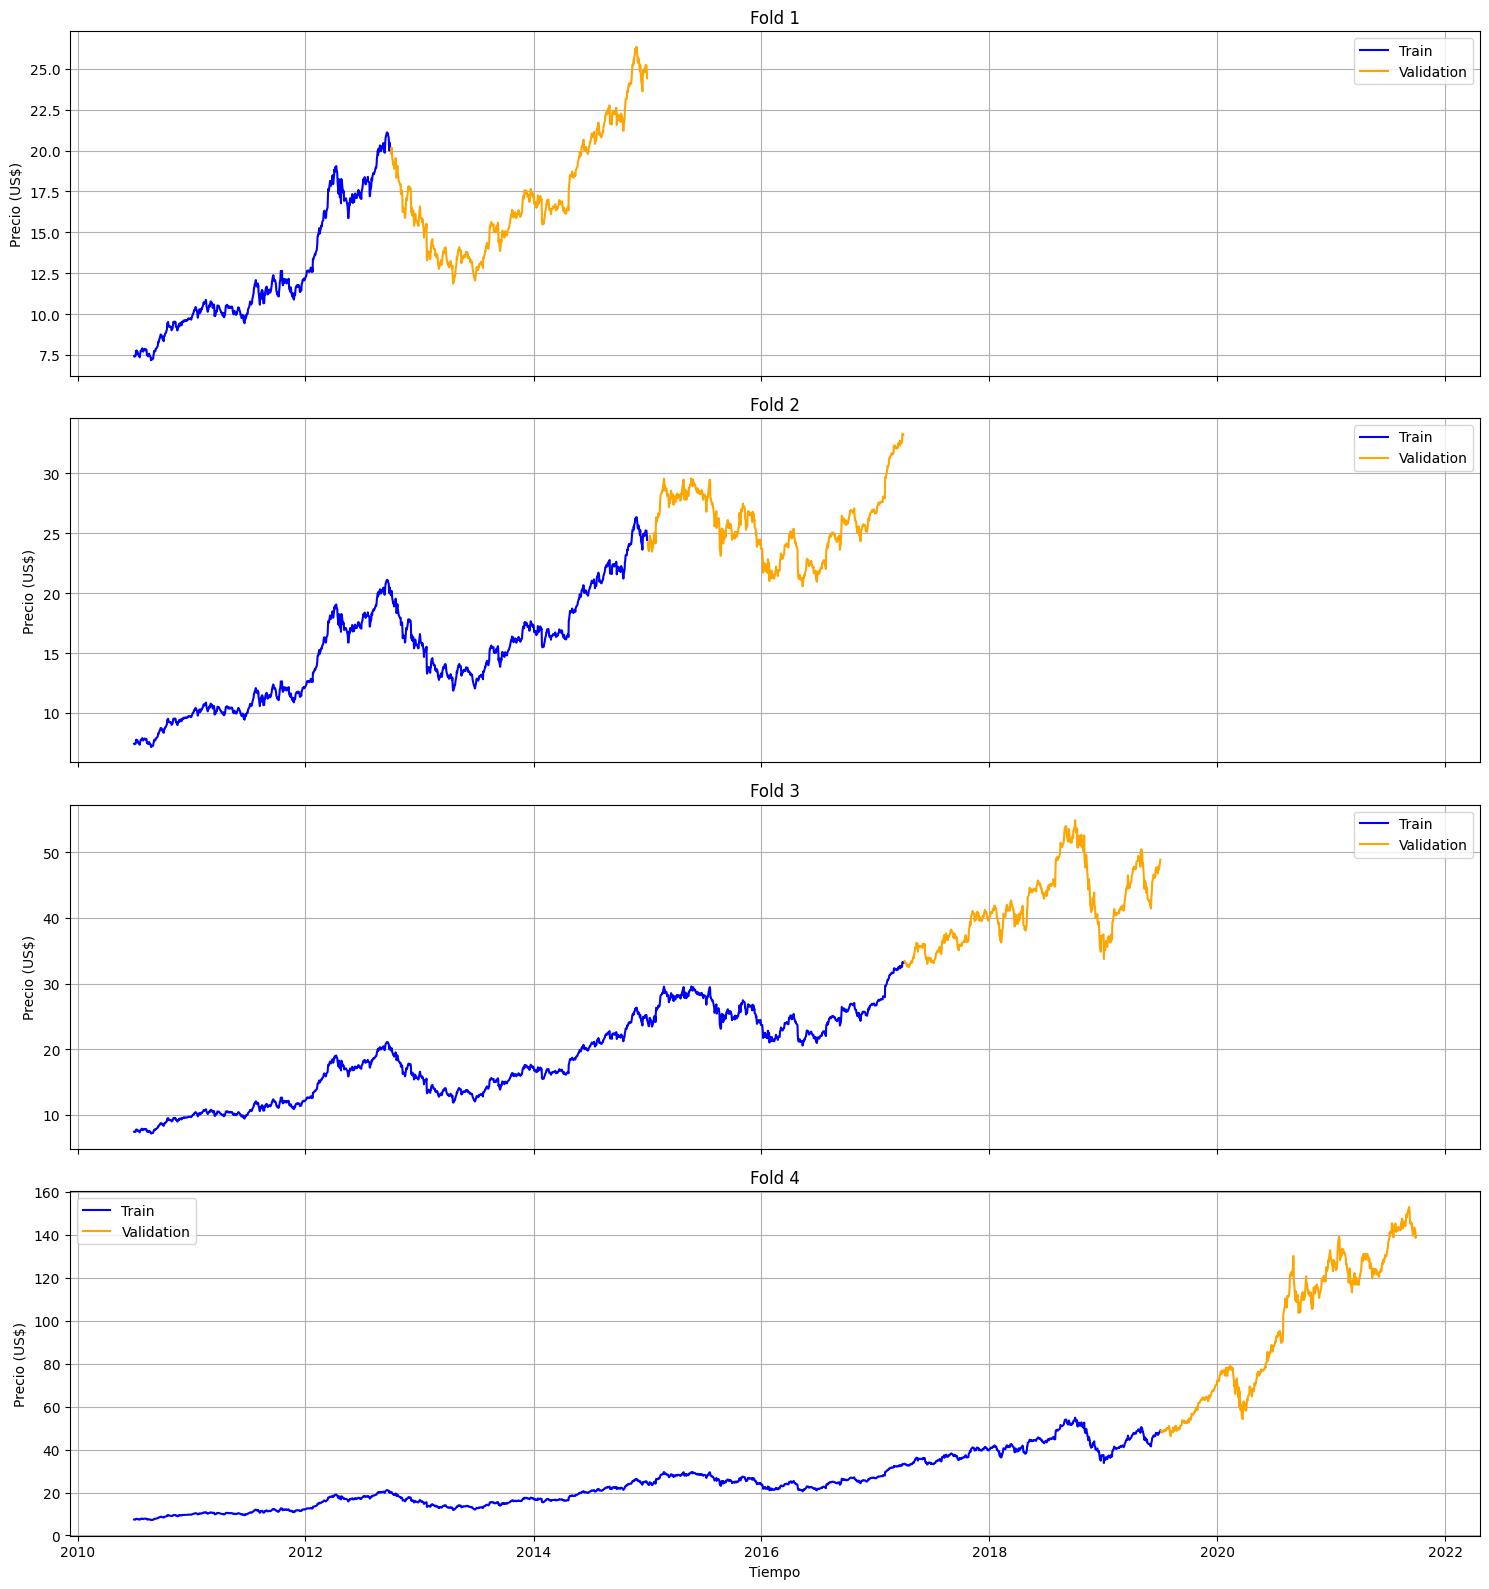

In [10]:
n_splits = 4
data_train_lst, data_validation_lst = K_fold(data_train, n_splits)
n_splits = len(data_train_lst)
fig, axs = plt.subplots(n_splits, 1, figsize=(15, 4 * n_splits), sharex=True)

# Ensure axs is iterable even if there is only 1 split
if n_splits == 1:
    axs = [axs]

for i in range(n_splits):
    axs[i].plot(data_train_lst[i], label='Train', color='blue')
    axs[i].plot(data_validation_lst[i], label='Validation', color='orange')
    axs[i].set_title(f'Fold {i + 1}')
    axs[i].set_ylabel('Precio (US$)')
    axs[i].legend()
    axs[i].grid(True)

plt.xlabel('Tiempo')
plt.tight_layout()
plt.show()

In [11]:
def create_sequences(data, steps_back, steps_ahead):
  X, Y = [], []
  data = np.array(data)
  for i in range(len(data) - steps_back - steps_ahead + 1):
    X.append(data[i : (i + steps_back)])
    Y.append(data[(i + steps_back) : (i + steps_back + steps_ahead)])
  return np.array(X), np.array(Y)

In [12]:
steps_back = 1
steps_ahead = 1
X_train, Y_train = create_sequences(data_train_lst[0], steps_back, steps_ahead)
X_val, Y_val = create_sequences(data_validation_lst[0], steps_back, steps_ahead)

In [13]:
X_train.shape

(567, 1)

In [14]:
Y_train.shape

(567, 1)

In [15]:
def normal_equation(X, Y):
    """
    Computes the closed-form solution to linear regression (normal equation)
    for multi-input and multi-output data.

    Parameters:
    X : numpy array of shape (N, D)
        Input features (N samples, D features)
    Y : numpy array of shape (N, K)
        Target values (N samples, K outputs)

    Returns:
    W : numpy array of shape (D + 1, K)
        Learned weights, where the first row corresponds to the bias/intercept.
    """
    # Add a column of ones to X for the bias/intercept term
    X_design = np.hstack([np.ones((X.shape[0], 1)), X])

    # Normal equation: W = (X^T * X)^-1 * X^T * Y
    # We use np.linalg.pinv (pseudo-inverse) as it's more robust to singular matrices
    W = np.linalg.pinv(X_design.T @ X_design) @ X_design.T @ Y

    return W

In [16]:
def predict(X, W):
  """
  Predicts the output for a given input using the learned weights.

  Parameters:
  X : numpy array of shape (N, D)
      Input features (N samples, D features)
  W : numpy array of shape (D + 1, K)
      Learned weights, where the first row corresponds to the bias/intercept.

  Returns:
  Y_pred : numpy array of shape (N, K)
  Predicted output values (N samples, K outputs).
  """
  # Add a column of ones to X for the bias/intercept term
  X_design = np.hstack([np.ones((X.shape[0], 1)), X])
  Y_pred = X_design @ W
  return Y_pred

In [17]:
W_hat = normal_equation(X_train, Y_train)
W_hat

array([[0.01715075],
       [1.00040961]])

In [18]:
Y_hat_train = predict(X_train, W_hat)
Y_hat_train.shape

(567, 1)

In [19]:
def calculate_rmse(Y, Y_hat):
  Y = np.array(Y)
  Y_hat = np.array(Y_hat)
  N = Y.shape[0] * Y.shape[1]
  return np.linalg.norm(Y - Y_hat, ord='fro')/N**0.5


In [20]:
rmse_train = calculate_rmse(Y_train, Y_hat_train)
rmse_train

np.float64(0.213254698327354)

In [21]:
Y_hat_val = predict(X_val, W_hat)
Y_hat_val.shape

(565, 1)

In [22]:
Y_hat_val = predict(X_val, W_hat)
rmse_val = calculate_rmse(Y_val, Y_hat_val)
rmse_val

np.float64(0.28227799389679065)

In [23]:
def RMSE_CV(steps_back, steps_ahead, trianing_dataset, n_splits):
  D_train_lst, D_validation_lst = K_fold(trianing_dataset, n_splits)
  n_splits = len(D_train_lst)
  RMSE_training_cv = 0
  RMSE_validation_cv = 0
  for i in range(n_splits):
    X_train_cv, Y_train_cv = create_sequences(data_train_lst[i], steps_back, steps_ahead)
    X_val_cv, Y_val_cv = create_sequences(data_validation_lst[i], steps_back, steps_ahead)
    W_hat = normal_equation(X_train_cv, Y_train_cv)
    Y_hat_train_cv = predict(X_train_cv, W_hat)
    Y_hat_val_cv = predict(X_val_cv, W_hat)
    RMSE_training_cv = calculate_rmse(Y_train_cv, Y_hat_train_cv) + RMSE_training_cv
    RMSE_validation_cv = calculate_rmse(Y_val_cv, Y_hat_val_cv) + RMSE_validation_cv
  RMSE_training_cv = RMSE_training_cv/n_splits
  RMSE_validation_cv = RMSE_validation_cv/n_splits
  return RMSE_training_cv, RMSE_validation_cv

In [24]:
rmse_training, rmse_validation = RMSE_CV(steps_back = 1, steps_ahead = 1, trianing_dataset = data_train, n_splits = 4)

In [25]:
rmse_training

np.float64(0.29872129805825137)

In [26]:
rmse_validation

np.float64(0.8630861401953924)

In [27]:
def plot_RMSE_steps_ahead(RMSE_training_lst, RMSE_validation_lstm, Curve):
  if Curve == "Training":
    steps_back_search = len(RMSE_training_lst)
    K_values = range(1, steps_back_search + 1)
    min_rmse_train = min(RMSE_training_lst)
    best_k_train = RMSE_training_lst.index(min_rmse_train) + 1
    plt.figure(figsize=(10, 6))
    # Mark the best K for training
    plt.scatter(best_k_train, RMSE_training_lst[best_k_train - 1], color='green', s=100, zorder=5, label=f'Mejor K Entrenamiento ({best_k_train})')
    plt.annotate(f'K={best_k_train}', (best_k_train, RMSE_training_lst[best_k_train - 1]), textcoords="offset points", xytext=(0,10), ha='center', color='green')
    plt.plot(K_values, RMSE_training_lst, label='RMSE de Entrenamiento', marker='o')
    plt.xlabel('Número de pasos atrás (K)')
    plt.ylabel('RMSE')
    plt.title('RMSE con diferente número de pasos atrás')
    plt.legend()
    plt.grid(True)
    plt.show()
  if Curve == "Validation":
    steps_back_search = len(RMSE_validation_lstm)
    K_values = range(1, steps_back_search + 1)
    min_rmse_val = min(RMSE_validation_lstm)
    best_k_val = RMSE_validation_lstm.index(min_rmse_val) + 1
    plt.figure(figsize=(10, 6))
    # Mark the best K for validation
    plt.scatter(best_k_val, RMSE_validation_lstm[best_k_val - 1], color='purple', s=100, zorder=5, label=f'Mejor K Validación ({best_k_val})')
    plt.annotate(f'K={best_k_val}', (best_k_val, RMSE_validation_lstm[best_k_val - 1]), textcoords="offset points", xytext=(0,10), ha='center', color='purple')
    plt.plot(K_values, RMSE_validation_lstm, label='RMSE de Validación', marker='o')
    plt.xlabel('Número de pasos atrás (K)')
    plt.ylabel('RMSE')
    plt.title('RMSE con diferente número de pasos atrás')
    plt.legend()
    plt.grid(True)
    plt.show()
  else:
    pass

In [28]:
def RMSE_CV_search_K(steps_back_search, steps_ahead, trianing_dataset, n_splits, plot):
  lista_RMSE_training = []
  lista_RMSE_validation = []
  for steps_back in range(1, steps_back_search + 1):
    rmse_training, rmse_validation = RMSE_CV(steps_back = steps_back, steps_ahead = steps_ahead, trianing_dataset = trianing_dataset, n_splits = n_splits)
    lista_RMSE_training.append(rmse_training)
    lista_RMSE_validation.append(rmse_validation)

  min_rmse_val = min(lista_RMSE_validation)
  best_k_val = lista_RMSE_validation.index(min_rmse_val) + 1
  print(f"The K with the lowest validation RMSE is: {best_k_val} (RMSE: {min_rmse_val:.4f})")
  plot_RMSE_steps_ahead(lista_RMSE_training, lista_RMSE_validation, Curve = plot)
  return best_k_val

The K with the lowest validation RMSE is: 1 (RMSE: 3.4967)


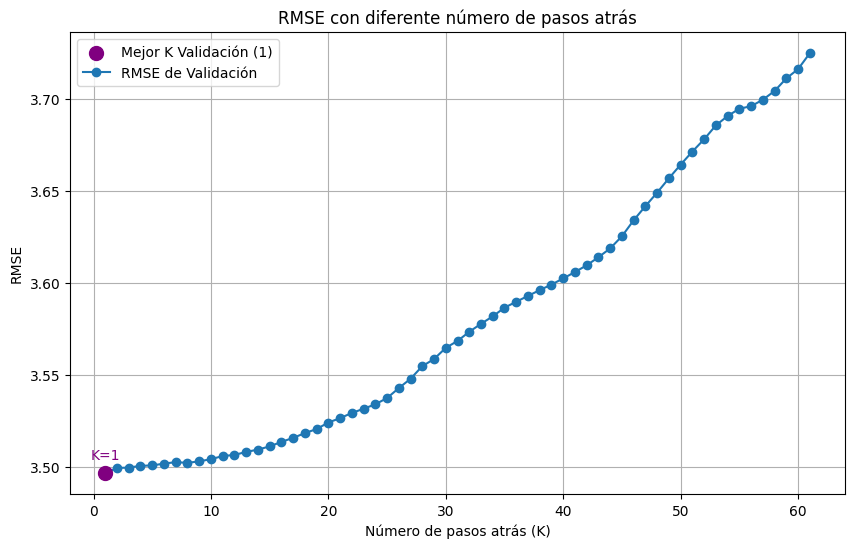

In [45]:
horizonte_temporal  = 31
best_k_val = RMSE_CV_search_K(steps_back_search = 61, steps_ahead = horizonte_temporal, trianing_dataset = data_train, n_splits = 4, plot = "Validation")

In [30]:
best_k_val

1

In [31]:
data_combined = pd.concat([data_train.iloc[-best_k_val:], data_test])

In [32]:
X_train, Y_train = create_sequences(data = data_train, steps_back = best_k_val, steps_ahead = horizonte_temporal)
X_test, Y_test = create_sequences(data = data_combined, steps_back = best_k_val, steps_ahead = horizonte_temporal)
W_hat_test = normal_equation(X_train, Y_train)
Y_hat_train = predict(X_train, W_hat_test)
Y_hat_test = predict(X_test, W_hat_test)
RMSE_training = calculate_rmse(Y_train, Y_hat_train)
RMSE_test = calculate_rmse(Y_test, Y_hat_test)

In [33]:
RMSE_training

np.float64(3.7160231410630655)

In [34]:
RMSE_test

np.float64(12.982595629870247)

In [35]:
Y_hat_test.shape

(1183, 31)

In [36]:
N, H = Y_hat_test.shape
T = N + H - 1
starts = np.arange(0, N, H)
y_hat_blocks = Y_hat_test[starts].ravel()
r = T - y_hat_blocks.size
Y_hat_test_vector = np.concatenate([y_hat_blocks, Y_hat_test[-1, H-r:]])

In [37]:
Y_hat_test_df = pd.DataFrame(Y_hat_test_vector, index=data_test.index, columns=['Predicted_Close'])
Y_hat_test_df

,Predicted_Close
Date,
2021-09-30,139.622632
2021-10-01,139.807584
2021-10-04,139.990535
2021-10-05,140.182116
2021-10-06,140.378620
...,...
2026-07-27,303.604416
2026-07-28,310.563623
2026-07-29,310.921953


In [38]:
data_test

,Close
,AAPL
Date,
2021-09-30,138.134018
2021-10-01,139.256699
2021-10-04,135.830200
2021-10-05,137.753357
2021-10-06,138.622147
...,...
2026-07-27,336.910004
2026-07-28,340.079987


In [42]:
X_future = np.array(data_test.iloc[-best_k_val:]).reshape(1, -1)
Y_hat_future = predict(X_future, W_hat_test)

In [43]:
last_date = data_test.index[-1]
future_dates = pd.bdate_range(start=last_date + pd.Timedelta(days=1), periods=Y_hat_future.shape[1])

future_df = pd.DataFrame(Y_hat_future[0], index=future_dates, columns=['Predicted_Close'])
Y_hat_test_df = pd.concat([Y_hat_test_df, future_df])


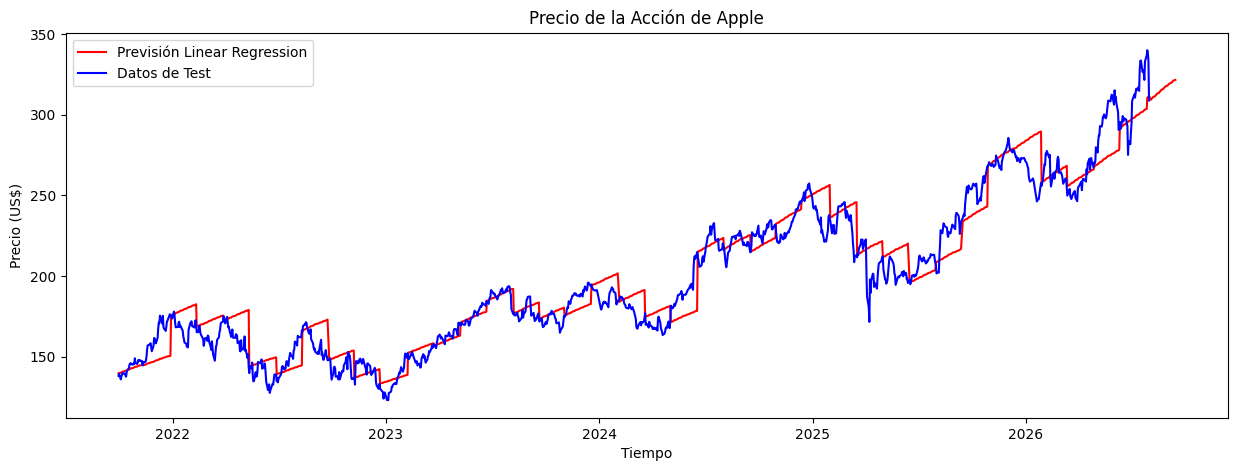

In [41]:
fig, ax = plt.subplots(figsize=(15, 5))
_ = plt.plot(Y_hat_test_df, color="r")
_ = plt.plot(data_test, color="b")
_ = plt.xlabel("Tiempo")
_ = plt.ylabel("Precio (US$)")
_ = plt.legend(['Previsión Linear Regression', 'Datos de Test'])
_ = plt.title("Precio de la Acción de Apple")
plt.show()